# Download the dataset (optional)

In [20]:
# Resolver rutas locales tanto desde la raíz como desde el directorio del notebook.
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
BASE = project_root / "data" / "RCAEval"

# Activar solo si es necesario descargar los archivos del dataset.
DOWNLOAD_DATA = False
if DOWNLOAD_DATA:
    from huggingface_hub import snapshot_download

    print(snapshot_download(
        repo_id="phamquiluan/RCAEval",
        repo_type="dataset",
        allow_patterns=["cases.parquet", "re2ss_*/metrics.parquet"],
        local_dir=BASE,
    ))

## Load RE2-SS

In [21]:
import sys

import numpy as np
import pandas as pd
from IPython.display import display

# Permitir los mismos imports desde la raíz y desde notebooks/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.configuration import TopologyConfig
from src.evaluation import IncidentSplit
from src.feature_builder import FeatureBuilder, assign_root_cause_labels
from src.ingestion import RCAEvalLoader
from src.window_association import associate_windows
from src.window_detector import WindowDetector

configuration = TopologyConfig(project_root / "config" / "topology.json")
loader = RCAEvalLoader(root=BASE, configuration=configuration)
metadata = {key: loader.load_metadata(key) for key in loader.list_incidents()}
split = IncidentSplit.load(project_root / "config" / "incident_split.json", metadata.values())
configuration.validate_calibration_split(split.development, split.test, split.metadata_sha256)

# Limitar la exploración a desarrollo; la reserva solo se valida por metadatos.
idx = pd.read_parquet(BASE / configuration.data_config["index_file"])
re2 = idx.loc[idx["case"].isin(split.development)].copy()

## Development metadata preview

In [22]:
# Resumir la partición por incidente y las etiquetas de desarrollo sin abrir la telemetría de reserva.
print(f"Reserved by incident: {len(split.development)} development / {len(split.test)} final holdout")
print("Development target distribution (one root cause per indexed incident)")
display(re2.head(), re2["root_cause_service"].value_counts().rename("incidents"))

Reserved by incident: 72 development / 18 final holdout
Development target distribution (one root cause per indexed incident)


,case,dataset,suite,system,system_name,root_cause_service,fault,fault_description,repetition,inject_time,n_metrics,n_timesteps,time_start,time_end,duration_minutes,normal_timesteps,faulty_timesteps,has_logs,n_logs,has_traces,n_traces,has_root_cause_file
465,re2ss_carts_cpu_1,RE2-SS,RE2,ss,Sock Shop,carts,cpu,CPU stress,1,1705596179,75,1441,1705595459,1705596899,24.0,720,721,True,86592,False,0,False
466,re2ss_carts_cpu_2,RE2-SS,RE2,ss,Sock Shop,carts,cpu,CPU stress,2,1705676689,78,1441,1705675969,1705677409,24.0,720,721,True,86451,False,0,False
468,re2ss_carts_delay_1,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,1,1705662624,79,1441,1705661904,1705663344,24.0,720,721,True,83040,False,0,False
469,re2ss_carts_delay_2,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,2,1705725124,75,1441,1705724404,1705725844,24.0,720,721,True,83145,False,0,False
470,re2ss_carts_delay_3,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,3,1705726713,75,1441,1705725993,1705727433,24.0,720,721,True,82548,False,0,False


root_cause_service
carts        15
user         15
catalogue    14
orders       14
payment      14
Name: incidents, dtype: int64

## Build clean development feature and target tables

The repository detector runs without labels and `FeatureBuilder` computes 153 candidate features using only data available at diagnosis time. Offline association uses injection metadata to select the first eligible diagnosis and assign one root-cause label per incident. The audit lists incidents that cannot produce supervised rows.

Keep only columns that are finite and nonconstant across all development rows. Do not impute or remove any supervised row. The persisted 72/18 split is fixed; the final holdout uses the same columns in the same order only if explicitly enabled below.

In [23]:
# Construir una fila por servicio e incidente asociado; conservar las omisiones en la auditoría.
def build_supervised_tables(incident_ids, expected_columns=None):
    builder = FeatureBuilder(configuration)
    feature_parts, target_parts, audit = [], [], []
    schema = expected_columns

    for incident_id in incident_ids:
        info = metadata[incident_id]
        updates = WindowDetector(configuration).run(loader.load_metrics(incident_id))
        # La inyección y la etiqueta solo intervienen en la asociación offline.
        association = associate_windows(info, (event for update in updates for event in update.events))
        status = association.status
        if association.selected is not None:
            batch = builder.build(association.selected)
            if not batch.identifiers["service"].eq(info.root_cause_service).any():
                status = "root_cause_not_observed"
            else:
                if schema is None:
                    schema = batch.X.columns
                if not schema.equals(batch.X.columns):
                    raise ValueError(f"Unexpected feature schema for {incident_id}")
                labels = assign_root_cause_labels(batch, info)
                index = pd.MultiIndex.from_frame(batch.identifiers[["incident_id", "service"]])
                feature_parts.append(batch.X.set_axis(index))
                target_parts.append(labels.rename("is_root_cause").to_frame().set_axis(index))
        audit.append({"incident_id": incident_id, "status": status})

    audit = pd.DataFrame(audit)
    if not feature_parts:
        return None, None, audit
    return pd.concat(feature_parts, verify_integrity=True), pd.concat(target_parts, verify_integrity=True), audit


def show_coverage(name, audit):
    omitted = audit.loc[audit["status"].ne("associated")]
    print(f"{name}: {len(audit) - len(omitted)}/{len(audit)} incidents associated")
    if not omitted.empty:
        display(omitted)


train_raw, Y_train, development_audit = build_supervised_tables(split.development)
show_coverage("Development", development_audit)
if train_raw is None:
    raise ValueError("No supervised development rows were produced.")

# Seleccionar solo columnas completas, finitas y variables en desarrollo.
finite = np.isfinite(train_raw.to_numpy(dtype=float, na_value=np.nan)).all(axis=0)
feature_columns = train_raw.columns[finite & train_raw.nunique().gt(1).to_numpy()]
if feature_columns.empty:
    raise ValueError("No finite, nonconstant development features remain.")
X_train = train_raw.loc[:, feature_columns]

assert X_train.index.equals(Y_train.index)
print(f"Development: {len(X_train):,} rows, {Y_train['is_root_cause'].sum():,} root causes")
print(f"Features: {train_raw.shape[1]} candidates, {len(feature_columns)} retained")
display(X_train.head(), Y_train.head())

Development: 71/72 incidents associated


,incident_id,status
13,re2ss_carts_socket_1,no_confirmed_alert


Development: 1,067 rows, 71 root causes
Features: 153 candidates, 44 retained


cpu__present  cpu__baseline_count  cpu__window_count  cpu__baseline_missing_fraction  cpu__window_missing_fraction  diskio__present  \
incident_id       service                                                                                                                                             
re2ss_carts_cpu_1 carts                  1.0                 60.0               15.0                             0.0                           0.0              0.0   
                  carts-db               1.0                 60.0               15.0                             0.0                           0.0              1.0   
                  catalogue              1.0                 60.0               15.0                             0.0                           0.0              0.0   
                  catalogue-db           1.0                 60.0               15.0                             0.0                           0.0              1.0   
                  front-end              1.0                 60.0               15.0                             0.0                           0.0              0.0   

                                diskio__baseline_count  diskio__window_count  diskio__baseline_missing_fraction  diskio__window_missing_fraction  error__present  \
incident_id       service                                                                                                                                          
re2ss_carts_cpu_1 carts                            0.0                   0.0                                1.0                              1.0             0.0   
                  carts-db                        60.0                  15.0                                0.0                              0.0             0.0   
                  catalogue                        0.0                   0.0                                1.0                              1.0             0.0   
                  catalogue-db                    60.0                  15.0                                0.0                              0.0             0.0   
                  front-end                        0.0                   0.0                                1.0                              1.0             1.0   

                                error__baseline_count  error__window_count  error__baseline_missing_fraction  error__window_missing_fraction  latency-50__present  \
incident_id       service                                                                                                                                           
re2ss_carts_cpu_1 carts                           0.0                  0.0                               1.0                             1.0                  1.0   
                  carts-db                        0.0                  0.0                               1.0                             1.0                  0.0   
                  catalogue                       0.0                  0.0                               1.0                             1.0                  1.0   
                  catalogue-db                    0.0                  0.0                               1.0                             1.0                  0.0   
                  front-end                      60.0                 15.0                               0.0                             0.0                  1.0   

                                latency-50__baseline_count  latency-50__window_count  latency-50__baseline_missing_fraction  latency-50__window_missing_fraction  \
incident_id       service                                                                                                                                          
re2ss_carts_cpu_1 carts                               60.0                      15.0                                    0.0                                  0.0   
                  carts-db                             0.0       

is_root_cause
incident_id       service                    
re2ss_carts_cpu_1 carts                     1
                  carts-db                  0
                  catalogue                 0
                  catalogue-db              0
                  front-end                 0

## Prepare one training sample per tree

Each tree gets a bootstrap sample of training rows and a fixed random subset of features. Test incidents are not used.

In [24]:
# Mostrar las variables asignadas a cada árbol sin exponer sus filas de entrenamiento.
def show_tree_samples(samples):
    display(pd.DataFrame({"tree": range(1, len(samples) + 1), "features": [list(features.columns) for features, _ in samples]}))


---

## Random Forest training

In [25]:
import json
import math
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from numbers import Real


# Una hoja conserva la fracción de positivos; una división añade el umbral y dos ramas.
@dataclass(frozen=True)
class _TreeNode:
    positive_fraction: float
    feature: str | None = None
    threshold: float | None = None
    left: '_TreeNode | None' = None
    right: '_TreeNode | None' = None


class RandomForest:
    """Train binary CART trees for scoring candidate root causes."""

    _EXPORT_VERSION = 1
    _MAX_DEPTH = 8

    def _prepare_tree_samples(
        self, X_train: pd.DataFrame, Y_train: pd.DataFrame, *, n_trees: int = 10, seed: int = 42
    ) -> list[tuple[pd.DataFrame, pd.DataFrame]]:
        """Draw bootstrap rows and a fixed feature subset for each tree."""
        if n_trees < 1 or X_train.empty or Y_train.empty or not X_train.index.equals(Y_train.index):
            raise ValueError("Provide at least one tree and nonempty, aligned training tables.")

        # Cada árbol recibe filas con reemplazo y un subconjunto fijo de variables sin reemplazo.
        rng = np.random.default_rng(seed)
        n_rows, k = X_train.shape
        n_features_per_tree = int(np.sqrt(k))
        samples = []
        for _ in range(n_trees):
            rows = rng.choice(n_rows, size=n_rows, replace=True)
            features = rng.choice(k, size=n_features_per_tree, replace=False)
            samples.append((X_train.iloc[rows, features].copy(), Y_train.iloc[rows].copy()))
        return samples

    def _build_tree(self, X_tree: pd.DataFrame, y_tree: pd.DataFrame) -> _TreeNode:
        """Grow one binary CART tree using only its assigned features."""
        values = X_tree.to_numpy(dtype=float)
        if y_tree.shape[1] != 1 or not y_tree.isin([0, 1]).to_numpy().all():
            raise ValueError("Provide exactly one binary target column.")
        if not np.isfinite(values).all():
            raise ValueError("Tree features must be finite; impute missing values before fitting.")
        labels = y_tree.iloc[:, 0].to_numpy(dtype=np.int64)
        max_depth, min_leaf = self._MAX_DEPTH, 2

        def grow(rows: np.ndarray, depth: int) -> _TreeNode:
            size = len(rows)
            positives = labels[rows].sum()
            fraction = float(positives / size)
            leaf = _TreeNode(fraction)
            if depth >= max_depth or size < 2 * min_leaf or positives in (0, size):
                return leaf

            # Comparar cortes entre valores distintos mediante la impureza de Gini ponderada.
            best_impurity = 2 * fraction * (1 - fraction)
            best_split = None
            for feature in range(values.shape[1]):
                ordered_rows = rows[np.argsort(values[rows, feature], kind="stable")]
                ordered_values = values[ordered_rows, feature]
                cuts = np.flatnonzero(ordered_values[:-1] < ordered_values[1:]) + 1
                cuts = cuts[(cuts >= min_leaf) & (size - cuts >= min_leaf)]
                if cuts.size == 0:
                    continue

                left_size, right_size = cuts, size - cuts
                left_pos = np.cumsum(labels[ordered_rows])[cuts - 1]
                right_pos = positives - left_pos
                left_rate, right_rate = left_pos / left_size, right_pos / right_size
                impurities = 2 * (
                    left_size * left_rate * (1 - left_rate)
                    + right_size * right_rate * (1 - right_rate)
                ) / size
                candidate = int(np.argmin(impurities))
                if impurities[candidate] < best_impurity - 1e-12:
                    best_impurity = impurities[candidate]
                    best_split = feature, ordered_rows, int(cuts[candidate])

            if best_split is None:
                return leaf
            feature, ordered_rows, cut = best_split
            lower, upper = values[ordered_rows[[cut - 1, cut]], feature]
            threshold = lower / 2 + upper / 2
            # Mantener el corte válido si el punto medio se redondea al valor superior.
            if not lower <= threshold < upper:
                threshold = lower
            return _TreeNode(
                fraction, X_tree.columns[feature], float(threshold),
                grow(ordered_rows[:cut], depth + 1),
                grow(ordered_rows[cut:], depth + 1),
            )

        return grow(np.arange(len(labels)), depth=0)

    def fit(self, X_train: pd.DataFrame, Y_train: pd.DataFrame) -> "RandomForest":
        """Prepare aligned bootstrap samples and build their trees concurrently."""
        schema = self._validate_schema(list(X_train.columns))
        # Comprobar todas las filas antes del muestreo, sin descartar ni imputar valores.
        if any(dtype.kind not in "iuf" for dtype in X_train.dtypes) or not np.isfinite(
            X_train.to_numpy(dtype=float, na_value=np.nan)
        ).all():
            raise ValueError("Training features must be finite real numbers.")
        samples = self._prepare_tree_samples(X_train, Y_train)
        with ThreadPoolExecutor() as executor:
            trees = list(executor.map(self._build_tree, *zip(*samples)))
        self._tree_samples, self._trees, self._feature_schema = samples, trees, schema
        return self

    @staticmethod
    def _validate_schema(names: list) -> tuple[str, ...]:
        if type(names) is not list or not names or any(type(name) is not str or not name for name in names):
            raise ValueError("Feature schema must be a nonempty list of nonempty strings.")
        if len(set(names)) != len(names):
            raise ValueError("Feature names must be unique.")
        return tuple(names)

    def _require_fitted(self) -> None:
        if not getattr(self, "_trees", None):
            raise RuntimeError("Fit or load a forest before using it.")

    @staticmethod
    def _finite_number(value: Real) -> float:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, Real):
            raise ValueError("Expected a finite real number.")
        try:
            number = float(value)
        except OverflowError as exc:
            raise ValueError("Expected a finite real number.") from exc
        if not math.isfinite(number):
            raise ValueError("Expected a finite real number.")
        return number

    @staticmethod
    def _predict_tree(node: _TreeNode, values: dict[str, float]) -> float:
        # Usar la misma comparación del entrenamiento y devolver únicamente el valor de la hoja.
        while node.feature is not None:
            node = node.left if values[node.feature] <= node.threshold else node.right
        return node.positive_fraction

    def predict_tree_scores(self, x: pd.Series) -> tuple[float, ...]:
        """Return the leaf score reached in each tree, in forest order."""
        self._require_fitted()
        if not isinstance(x, pd.Series):
            raise TypeError("Provide one feature row as a pandas Series.")
        # Validar el conjunto completo de nombres; el orden de la fila no afecta el recorrido.
        if set(self._validate_schema(list(x.index))) != set(self._feature_schema):
            raise ValueError("Feature names must match the fitted schema exactly.")
        values = {name: self._finite_number(value) for name, value in x.items()}
        return tuple(self._predict_tree(tree, values) for tree in self._trees)

    def predict(self, x: pd.Series) -> float:
        """Return the root-cause score for one service feature row."""
        scores = self.predict_tree_scores(x)
        return math.fsum(scores) / len(scores)

    @classmethod
    def _encode_tree(cls, node: _TreeNode) -> dict:
        if node.feature is None:
            return {"score": node.positive_fraction}
        return {"feature": node.feature, "threshold": node.threshold,
                "left": cls._encode_tree(node.left), "right": cls._encode_tree(node.right)}

    def export(self, path: str | Path) -> None:
        """Write inference-only JSON to a new file."""
        self._require_fitted()
        # Guardar solo lo necesario para inferencia; el modo exclusivo evita sobrescrituras.
        payload = {"version": self._EXPORT_VERSION, "features": list(self._feature_schema),
                   "trees": [self._encode_tree(tree) for tree in self._trees]}
        text = json.dumps(payload, allow_nan=False, indent=2)
        with Path(path).open("x", encoding="utf-8") as stream:
            stream.write(text + "\n")

    @classmethod
    def _decode_tree(cls, node: dict, features: set[str], depth: int = 0) -> _TreeNode:
        # Distinguir hojas de divisiones completas y validar cada rama antes de crear el modelo.
        if type(node) is not dict or depth > cls._MAX_DEPTH:
            raise ValueError("Invalid node or tree depth.")
        if node.keys() == {"score"}:
            score = cls._finite_number(node["score"])
            if not 0 <= score <= 1:
                raise ValueError("Leaf score must be in [0, 1].")
            return _TreeNode(score)
        if node.keys() != {"feature", "threshold", "left", "right"}:
            raise ValueError("Invalid split node fields.")
        feature = node["feature"]
        if type(feature) is not str or feature not in features:
            raise ValueError("Split feature is not in the inference schema.")
        threshold = cls._finite_number(node["threshold"])
        return _TreeNode(0.0, feature, threshold,
                         cls._decode_tree(node["left"], features, depth + 1),
                         cls._decode_tree(node["right"], features, depth + 1))

    @classmethod
    def from_export(cls, path: str | Path) -> "RandomForest":
        """Construct a forest from a model saved with export."""
        def unique_keys(pairs):
            fields = dict(pairs)
            if len(fields) != len(pairs):
                raise ValueError("Duplicate JSON fields are not allowed.")
            return fields

        try:
            payload = json.loads(Path(path).read_text(encoding="utf-8"), object_pairs_hook=unique_keys)
        except RecursionError as exc:
            raise ValueError("Model JSON is nested too deeply.") from exc
        if type(payload) is not dict or payload.keys() != {"version", "features", "trees"}:
            raise ValueError("Invalid forest export fields.")
        if type(payload["version"]) is not int or payload["version"] != cls._EXPORT_VERSION:
            raise ValueError("Unsupported forest export version.")
        schema = cls._validate_schema(payload["features"])
        if type(payload["trees"]) is not list or not payload["trees"]:
            raise ValueError("Forest export must contain at least one tree.")
        features = set(schema)
        model = cls()
        model._trees = [cls._decode_tree(node, features) for node in payload["trees"]]
        model._feature_schema = schema
        return model


In [26]:
# Entrenar el bosque y mostrar el subconjunto de variables de cada árbol.
forest = RandomForest().fit(X_train, Y_train)
show_tree_samples(forest._tree_samples)
print(f"Built {len(forest._trees)} trees.")

,tree,features
0,1,"[error__baseline_missing_fraction, socket__bas..."
1,2,"[error__window_missing_fraction, latency-50__w..."
2,3,"[latency-90__window_missing_fraction, workload..."
3,4,"[mem__baseline_count, mem__baseline_std, diski..."
4,5,"[latency-50__window_missing_fraction, workload..."
5,6,"[diskio__window_count, latency-50__baseline_mi..."
6,7,"[error__baseline_missing_fraction, mem__baseli..."
7,8,"[workload__baseline_missing_fraction, diskio__..."
8,9,"[latency-90__baseline_missing_fraction, diskio..."
9,10,"[cpu__baseline_missing_fraction, mem__baseline..."


Built 10 trees.


## Export, load, and score development rows

This example scores rows used for development. It does not measure validation performance or use the final holdout.

In [27]:
from tempfile import TemporaryDirectory

# Usar un directorio temporal bajo artifacts/ para no sobrescribir ni dejar modelos persistentes.
artifact_root = project_root / "artifacts"
artifact_root.mkdir(exist_ok=True)
with TemporaryDirectory(prefix="notebook-forest-", dir=artifact_root) as export_dir:
    model_path = Path(export_dir) / "forest.json"
    forest.export(model_path)
    loaded_forest = RandomForest.from_export(model_path)

# Consultar tres filas de desarrollo con el esquema seleccionado; no estimar rendimiento.
demo_rows = X_train.head(3)
tree_scores = [loaded_forest.predict_tree_scores(row) for _, row in demo_rows.iterrows()]
demo_scores = pd.DataFrame(tree_scores, index=demo_rows.index,
                           columns=[f"tree_{i}" for i in range(1, len(tree_scores[0]) + 1)])
demo_scores["forest_score"] = [loaded_forest.predict(row) for _, row in demo_rows.iterrows()]
display(demo_scores)

tree_1    tree_2    tree_3  tree_4    tree_5    tree_6    tree_7    tree_8  tree_9  tree_10  forest_score
incident_id       service                                                                                                             
re2ss_carts_cpu_1 carts         0.0  0.009901  0.141975     0.5  0.011673  0.007407  0.333333  0.006993    0.25      0.0      0.126128
                  carts-db      0.0  0.000000  0.000000     0.0  0.000000  0.000000  0.000000  0.000000    0.00      0.0      0.000000
                  catalogue     0.0  0.009901  0.141975     0.0  0.011673  0.007407  0.000000  0.006993    0.00      0.0      0.017795

## Detailed exploration

In [28]:
# Explorar solo los casos de desarrollo: cobertura, faltantes y cambios descriptivos.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)


def titulo(txt):
    print("\n" + "=" * 75)
    print(txt)
    print("=" * 75)


def resumen(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "nulos_%": (
            df.isna().mean() * 100
        ).round(2),
        "unicos": df.nunique(dropna=True),
    })


def muestra(df, nombre, n=5):
    titulo(nombre)
    print("Dimensiones:", df.shape)
    print("Memoria (MiB):", round(
        df.memory_usage(deep=True).sum()
        / 1024**2, 2
    ))
    display(resumen(df))
    display(df.head(n))


titulo("1. INFORMACIÓN GENERAL")
print("Casos del subconjunto:", len(re2))
print("Columnas del índice:", len(re2.columns))
display(re2.head())
display(resumen(re2))

# 2. Etiquetas y distribución
titulo("2. TIPOS DE FALLAS")
display(
    re2["fault"].value_counts()
    .rename_axis("falla")
    .reset_index(name="casos")
)

titulo("3. SERVICIOS CAUSANTES")
display(
    re2["root_cause_service"]
    .value_counts()
    .rename_axis("servicio")
    .reset_index(name="casos")
)

titulo("4. FALLAS POR SERVICIO")
display(pd.crosstab(
    re2["root_cause_service"],
    re2["fault"]
))

# 3. Cobertura general
titulo("5. COBERTURA DEL DATASET")
cols = [
    "n_metrics", "n_timesteps",
    "duration_minutes",
    "normal_timesteps",
    "faulty_timesteps",
    "n_logs", "n_traces"
]
cols = [c for c in cols if c in re2.columns]

display(re2[cols].describe().T)

# 4. Archivos disponibles
titulo("6. ARCHIVOS DESCARGADOS")

filas = []
for _, fila in re2.iterrows():
    carp = BASE / fila["case"]
    reg = {"caso": fila["case"]}
    for nombre in [
        "metrics.parquet",
        "logs.parquet",
        "traces.parquet",
        "inject_time.txt"
    ]:
        arch = carp / nombre
        reg[nombre] = arch.exists()
        reg[nombre + "_MiB"] = (
            round(arch.stat().st_size / 1024**2, 2)
            if arch.exists() else np.nan
        )
    filas.append(reg)

archivos = pd.DataFrame(filas)
display(archivos.head(10))

print("Disponibilidad por archivo:")
display(
    archivos[
        [c for c in archivos.columns
         if c.endswith((".parquet", ".txt"))]
    ].sum()
)

# 5. Seleccionar un caso disponible
validos = [
    c for c in re2["case"]
    if (BASE / c / "metrics.parquet").exists()
]

if not validos:
    raise FileNotFoundError(
        "No RE2-SS metrics found. Run the download cell first."
    )

caso = validos[0]
carp = BASE / caso
meta = re2.loc[re2["case"] == caso].iloc[0]

titulo("7. CASO SELECCIONADO")
print("Caso:", caso)
print("Servicio raíz:", meta["root_cause_service"])
print("Tipo de falla:", meta["fault"])
print("Repetición:", meta["repetition"])
print("Inyección Unix:", meta["inject_time"])
print("Inyección UTC:", pd.to_datetime(
    meta["inject_time"], unit="s", utc=True
))

# 6. Métricas
met = loader.load_metrics(caso).frame
muestra(met, "8. ESTRUCTURA DE MÉTRICAS")

titulo("9. ESTADÍSTICAS DE MÉTRICAS")
num = met.select_dtypes(include=np.number)
num = num.drop(columns=["time"], errors="ignore")

display(num.describe().T)

titulo("10. MÉTRICAS CONSTANTES")
const = num.columns[
    num.nunique(dropna=True) <= 1
].tolist()
print("Cantidad:", len(const))
print(const)

titulo("11. MÉTRICAS CON MÁS NULOS")
display(
    resumen(num)
    .sort_values("nulos_%", ascending=False)
    .head(20)
)

# 7. Temporalidad
titulo("12. ANÁLISIS TEMPORAL")

if "time" in met.columns:
    t = pd.to_numeric(
        met["time"], errors="coerce"
    ).dropna().sort_values().drop_duplicates()

    print("Inicio UTC:", pd.to_datetime(
        t.min(), unit="s", utc=True
    ))
    print("Fin UTC:", pd.to_datetime(
        t.max(), unit="s", utc=True
    ))

    dt = t.diff().dropna()
    print("Intervalos (segundos):")
    display(dt.describe())

    iny = int(meta["inject_time"])
    normal = met[met["time"] < iny]
    falla = met[met["time"] >= iny]

    print("Filas normales:", len(normal))
    print("Filas posteriores:", len(falla))

# 8. Comparación antes/después
titulo("13. CAMBIOS EN MÉTRICAS")

if len(normal) and len(falla):
    a = normal[num.columns].mean()
    b = falla[num.columns].mean()

    comp = pd.DataFrame({
        "media_normal": a,
        "media_posterior": b,
        "diferencia": b - a,
    })
    comp["cambio_abs"] = (
        comp["diferencia"].abs()
    )

    display(
        comp.sort_values(
            "cambio_abs", ascending=False
        ).head(20)
    )

# 9. Registros y trazas: solo exploración, no son entradas del bosque.
for nombre in ["logs", "traces"]:
    arch = carp / f"{nombre}.parquet"

    if arch.exists():
        df = pd.read_parquet(arch)
        muestra(
            df,
            f"14. ESTRUCTURA DE {nombre.upper()}"
        )

        if nombre == "traces":
            for col in ["serviceName", "statusCode"]:
                if col in df.columns:
                    print(f"Distribución de {col}:")
                    display(
                        df[col].value_counts().head(20)
                    )
    else:
        print(f"No existe {nombre}.parquet")

# 10. Compatibilidad entre casos
titulo("15. CONSISTENCIA DE CARACTERÍSTICAS")

esquemas = {}
for c in validos:
    columnas = loader.load_metrics(c).frame.columns
    esquemas[c] = set(columnas) - {"time"}

union = set().union(*esquemas.values())
inter = set.intersection(*esquemas.values())

print("Casos inspeccionados:", len(esquemas))
print("Métricas distintas:", len(union))
print("Métricas comunes:", len(inter))
print("Métricas no comunes:", len(union - inter))
print("Ejemplos de métricas comunes:")
print(sorted(inter)[:30])

titulo("EXPLORACIÓN FINALIZADA")


1. INFORMACIÓN GENERAL
Casos del subconjunto: 72
Columnas del índice: 22


,case,dataset,suite,system,system_name,root_cause_service,fault,fault_description,repetition,inject_time,n_metrics,n_timesteps,time_start,time_end,duration_minutes,normal_timesteps,faulty_timesteps,has_logs,n_logs,has_traces,n_traces,has_root_cause_file
465,re2ss_carts_cpu_1,RE2-SS,RE2,ss,Sock Shop,carts,cpu,CPU stress,1,1705596179,75,1441,1705595459,1705596899,24.0,720,721,True,86592,False,0,False
466,re2ss_carts_cpu_2,RE2-SS,RE2,ss,Sock Shop,carts,cpu,CPU stress,2,1705676689,78,1441,1705675969,1705677409,24.0,720,721,True,86451,False,0,False
468,re2ss_carts_delay_1,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,1,1705662624,79,1441,1705661904,1705663344,24.0,720,721,True,83040,False,0,False
469,re2ss_carts_delay_2,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,2,1705725124,75,1441,1705724404,1705725844,24.0,720,721,True,83145,False,0,False
470,re2ss_carts_delay_3,RE2-SS,RE2,ss,Sock Shop,carts,delay,network delay,3,1705726713,75,1441,1705725993,1705727433,24.0,720,721,True,82548,False,0,False


,tipo,nulos,nulos_%,unicos
case,str,0,0.0,72
dataset,str,0,0.0,1
suite,str,0,0.0,1
system,str,0,0.0,1
system_name,str,0,0.0,1
root_cause_service,str,0,0.0,5
fault,str,0,0.0,6
fault_description,str,0,0.0,6
repetition,int64,0,0.0,3
inject_time,int64,0,0.0,72



2. TIPOS DE FALLAS


,falla,casos
0,cpu,12
1,delay,12
2,disk,12
3,loss,12
4,mem,12
5,socket,12



3. SERVICIOS CAUSANTES


... (17 outputs left out)

count    1440.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: time, dtype: float64

Filas normales: 720
Filas posteriores: 721

13. CAMBIOS EN MÉTRICAS


,media_normal,media_posterior,diferencia,cambio_abs
carts_mem,2.072481e+08,2.130095e+08,5.761381e+06,5.761381e+06
carts-db_mem,7.943071e+07,8.240345e+07,2.972740e+06,2.972740e+06
user-db_mem,4.733726e+07,4.981075e+07,2.473490e+06,2.473490e+06
orders-db_mem,4.026441e+07,4.135652e+07,1.092108e+06,1.092108e+06
queue-master_mem,2.652533e+08,2.655816e+08,3.282702e+05,3.282702e+05
orders_mem,3.273551e+08,3.276304e+08,2.753428e+05,2.753428e+05
carts-db_diskio,1.933343e+06,2.185288e+06,2.519455e+05,2.519455e+05
front-end_mem,1.032873e+08,1.031104e+08,-1.769781e+05,1.769781e+05
rabbitmq_mem,1.002310e+08,1.003225e+08,9.152400e+04,9.152400e+04
shipping_mem,3.059457e+08,3.058620e+08,-8.372528e+04,8.372528e+04


No existe logs.parquet
No existe traces.parquet

15. CONSISTENCIA DE CARACTERÍSTICAS
Casos inspeccionados: 72
Métricas distintas: 86
Métricas comunes: 73
Métricas no comunes: 13
Ejemplos de métricas comunes:
['carts-db_cpu', 'carts-db_diskio', 'carts-db_mem', 'carts-db_socket', 'carts_cpu', 'carts_latency-50', 'carts_latency-90', 'carts_mem', 'carts_socket', 'carts_workload', 'catalogue-db_cpu', 'catalogue-db_diskio', 'catalogue-db_mem', 'catalogue-db_socket', 'catalogue_cpu', 'catalogue_latency-50', 'catalogue_latency-90', 'catalogue_mem', 'catalogue_socket', 'catalogue_workload', 'front-end_cpu', 'front-end_latency-50', 'front-end_latency-90', 'front-end_mem', 'front-end_socket', 'front-end_workload', 'orders-db_cpu', 'orders-db_diskio', 'orders-db_mem', 'orders-db_socket']

EXPLORACIÓN FINALIZADA


## Final holdout (opt-in)

After running the setup, development data, and forest training cells, set `EVALUATE_FINAL_HOLDOUT = True` and run the two cells below. This evaluates the 18 reserved incidents with the fixed development feature set and fitted forest. Do not use these results to tune the detector, features, or model.

An incident is scored only if it has an associated diagnosis, its true root is among the candidates, and every candidate can be scored. The top-scoring service is the only predicted positive; exact score ties are broken by ascending service name. The audit reports tied top scores and distinguishes missing diagnoses from scoring failures.

The confusion matrix and binary metrics are candidate-level and conditional on scorable incidents. Precision and recall coincide because there is exactly one predicted positive and one true positive label per scored incident, so both denominators equal the number of scored incidents. F1 therefore has the same value, which also equals conditional Top-1 accuracy. Zero-denominator metrics are reported as 0; the rank chart includes unscorable incidents separately.

In [29]:
# Activar solo para la evaluación final; no cambiar el bosque ni el esquema de desarrollo.
EVALUATE_FINAL_HOLDOUT = False
holdout_results = None
if EVALUATE_FINAL_HOLDOUT:
    test_raw, Y_test, holdout_audit = build_supervised_tables(split.test, expected_columns=train_raw.columns)
    X_test = None if test_raw is None else test_raw.loc[:, feature_columns]
    if X_test is not None:
        assert X_test.columns.equals(X_train.columns) and X_test.index.equals(Y_test.index)

    # Conservar los 18 casos en la auditoría, aunque no produzcan filas evaluables.
    audit_rows = []
    confusion = np.zeros((2, 2), dtype=int)
    for case in holdout_audit.itertuples(index=False):
        entry = dict(incident_id=case.incident_id, association_status=case.status,
                     scoring_status="not_associated", candidates=None, predicted_service=None,
                     root_rank=None, top_tie_size=None)
        audit_rows.append(entry)
        if case.status != "associated":
            continue
        rows = X_test.xs(case.incident_id, level="incident_id")
        truth = Y_test.xs(case.incident_id, level="incident_id")["is_root_cause"]
        assert rows.index.equals(truth.index) and truth.isin([0, 1]).all() and truth.sum() == 1
        entry["candidates"] = len(rows)

        # Si falla un candidato, excluir el incidente completo sin imputar ni recortar candidatos.
        if not np.isfinite(rows.to_numpy(dtype=float, na_value=np.nan)).all():
            entry["scoring_status"] = "nonfinite_features"
            continue
        scores = [(service, forest.predict(row)) for service, row in rows.iterrows()]
        if not all(np.isfinite(score) for _, score in scores):
            entry["scoring_status"] = "nonfinite_scores"
            continue

        # Desempatar por nombre de servicio y contar los empates exactos en el primer puesto.
        ranked = sorted(scores, key=lambda item: (-item[1], item[0]))
        winner, best_score = ranked[0]
        entry.update(scoring_status="scored", predicted_service=winner,
                     root_rank=next(rank for rank, (service, _) in enumerate(ranked, 1)
                                    if truth.at[service] == 1),
                     top_tie_size=sum(score == best_score for _, score in ranked))
        for service, label in truth.items():
            confusion[int(label), int(service == winner)] += 1

    holdout_results = pd.DataFrame(audit_rows).astype(
        {"candidates": "Int64", "root_rank": "Int64", "top_tie_size": "Int64"}
    )
else:
    print("Final holdout not evaluated. Set EVALUATE_FINAL_HOLDOUT = True to run it.")

Associated: 15/18; scored: 15/18
Not associated: 3; associated but unscorable: 0
Scored incidents with a tie for first: 0


,incident_id,association_status,scoring_status,candidates,predicted_service,root_rank,top_tie_size
0,re2ss_carts_cpu_3,associated,scored,15,carts,1,1
1,re2ss_carts_mem_1,associated,scored,15,carts,1,1
2,re2ss_carts_socket_3,associated,scored,15,carts,1,1
3,re2ss_catalogue_delay_3,associated,scored,15,catalogue,1,1
4,re2ss_catalogue_disk_1,no_associable_diagnosis,not_associated,<NA>,NaN,<NA>,<NA>
5,re2ss_catalogue_loss_3,associated,scored,15,catalogue,1,1
6,re2ss_catalogue_mem_3,associated,scored,15,catalogue,1,1
7,re2ss_orders_delay_3,associated,scored,15,orders,1,1
8,re2ss_orders_disk_1,associated,scored,15,catalogue,2,1
9,re2ss_orders_loss_3,associated,scored,15,orders,1,1


Predicted,0,1
Actual,,
0,208,2
1,2,13


Precision    0.866667
Recall       0.866667
F1           0.866667
Name: Scored candidates, dtype: float64

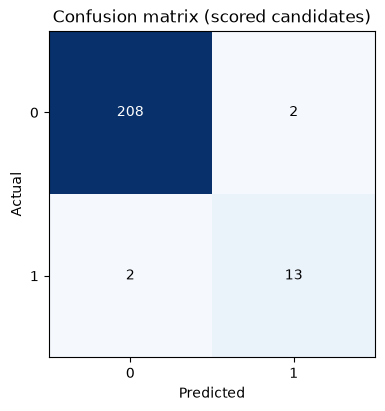

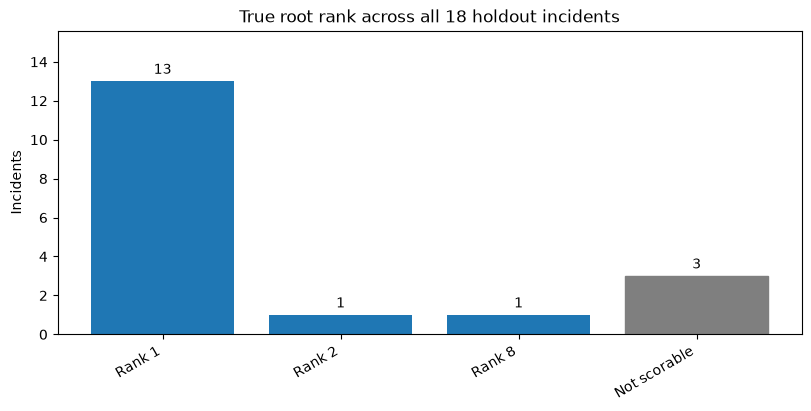

In [30]:
import matplotlib.pyplot as plt

if holdout_results is not None:
    # Informar primero la cobertura; las métricas binarias no incluyen incidentes omitidos.
    total = len(holdout_results)
    associated = int(holdout_results["association_status"].eq("associated").sum())
    ranks = holdout_results["root_rank"].dropna()
    print(f"Associated: {associated}/{total}; scored: {len(ranks)}/{total}")
    print(f"Not associated: {total - associated}; associated but unscorable: {associated - len(ranks)}")
    print(f"Scored incidents with a tie for first: {holdout_results['top_tie_size'].gt(1).sum()}")
    display(holdout_results)

    # Filas reales y columnas predichas, ambas en el orden explícito [0, 1].
    matrix = pd.DataFrame(confusion, index=pd.Index([0, 1], name="Actual"),
                          columns=pd.Index([0, 1], name="Predicted"))
    tn, fp, fn, tp = map(int, confusion.ravel())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    display(matrix, pd.Series({"Precision": precision, "Recall": recall, "F1": f1},
                              name="Scored candidates"))

    # La matriz solo incluye candidatos evaluados; cada celda muestra su conteo absoluto.
    fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
    image = ax.imshow(confusion, cmap="Blues", vmin=0)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix (scored candidates)")
    for (actual, predicted), count in np.ndenumerate(confusion):
        color = "white" if image.norm(count) > 0.5 else "black"
        ax.text(predicted, actual, str(count), ha="center", va="center", color=color)
    plt.show()

    # Ordenar las posiciones numéricamente y añadir los casos no evaluables al final.
    counts = [(f"Rank {rank}", count) for rank, count in ranks.value_counts().sort_index().items()]
    counts.append(("Not scorable", total - len(ranks)))
    labels, values = zip(*counts)
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    bars = ax.bar(labels, values)
    bars[-1].set_color("tab:gray")
    ax.bar_label(bars, padding=3)
    ax.set_ylim(0, max(1, max(values)) * 1.2)
    ax.set(ylabel="Incidents", title=f"True root rank across all {total} holdout incidents")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    plt.show()